In [8]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
sys.path.append('../../')
from utils_plots import apply_plot_style, get_layers, load_ii_curves, linestyle_for_language, _min_token_length
eps = 1E-7
colors, markers, _linestyles = apply_plot_style()
plot_id = 0
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()

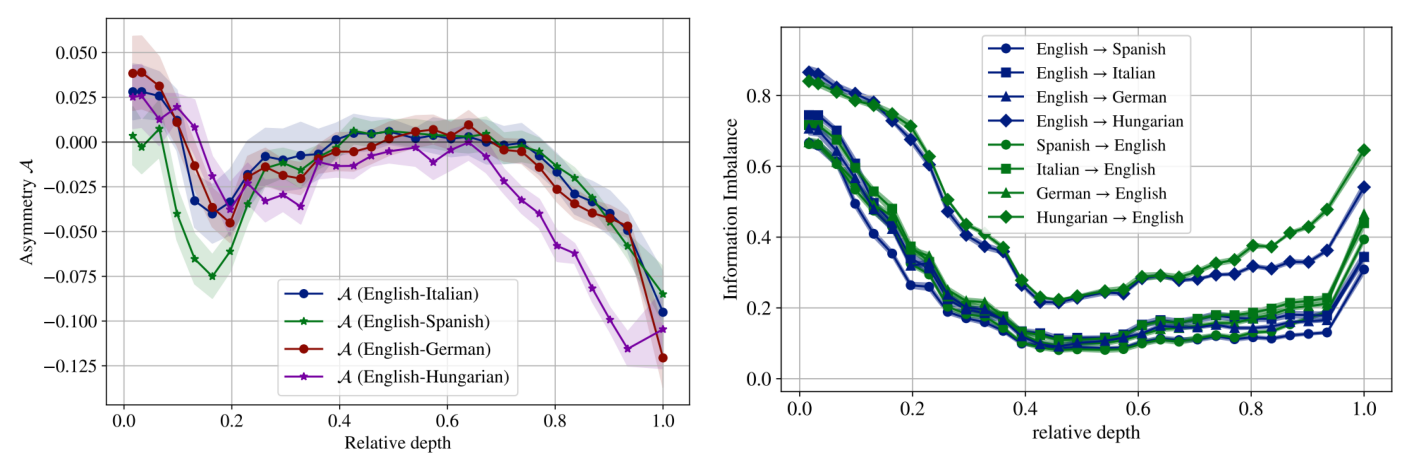

Saved: ../results/figs/fig1-combined.pdf


In [ ]:
# Combine selected figure PDFs into one 1x3 panel
from pathlib import Path
import matplotlib.pyplot as plt

try:
    import pypdfium2 as pdfium
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        "pypdfium2 is required to render PDF pages. Install it with: pip install pypdfium2"
    ) from e

FIGS_DIR = Path("../results/figs")
PDFS = [
    FIGS_DIR / "Asymmetry-EN-multi.pdf",
    FIGS_DIR / "english-pivot.pdf",
]

for pdf_path in PDFS:
    if not pdf_path.exists():
        raise FileNotFoundError(f"Missing file: {pdf_path}")


def first_page_as_rgb(pdf_path: Path, scale: float = 2.0):
    pdf = pdfium.PdfDocument(str(pdf_path))
    page = pdf[0]
    bitmap = page.render(scale=scale)
    pil_img = bitmap.to_pil()
    page.close()
    pdf.close()
    return pil_img

images = [first_page_as_rgb(pdf_path) for pdf_path in PDFS]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, img, pdf_path in zip(axes, images, PDFS):
    ax.imshow(img)
    ax.axis("off")

out_path = FIGS_DIR / "fig1-combined.pdf"
fig.savefig(out_path, bbox_inches="tight")
plt.show()
print(f"Saved: {out_path}")